# **Replica pipeline**

***

## Imports, costanti e funzioni

In [1]:
%pip install -q numpy pandas scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

DATA_DIR = Path("path/to/VitaStress/data")  # <-- inserire il percorso della cartella data/ del dataset
OUT_DIR = Path("analysis")  # output (creata in automatico se non esiste)

# --- scelte della pipeline
# finestre a cavallo della fine di una fase:
#   "full"  -> scartate, si tengono solo le finestre interamente dentro la fase
#   "start" -> si tengono quelle che iniziano dentro la fase (conteggi coerenti con la Fig. 8)
LABEL_RULE = "start"
# su quali finestre di ogni soggetto si calcolano media e std dello z-score:
#   "phases" -> le finestre delle 4 fasi
#   "experiment" -> dalla prima all'ultima annotation;
#   "recording" -> tutta la registrazione
ZSCORE_BASE = "phases"
# assi dell'accelerometro da invertire per i soggetti col braccialetto ruotato di 180° attorno a X.
# Vuoto = dati come pubblicati (riproduzione del paper); correzione: {"ddca342b": ["accY", "accZ"]}
FLIPPED_AXES = {"ddca342b": ["accY", "accZ"]}
#FLIPPED_AXES = {}

WINDOW = pd.Timedelta("30s")  # "resampled to have a sampling frequency of 1/30 seconds" (sez. 3.6)

# (Start, Stop) di ogni fase in *_annotation.csv; "public" è solo il discorso, senza preparazione
PHASE_LABELS = {
    "baseline": ("Baseline Start (Start of Experiment)", "Baseline Stop"),
    "cognitive": ("Cognitive: Start", "Cognitive: Stop"),
    "physical": ("Physical: Start", "Physical: Stop"),
    "public": ("Public Speaking Start", "Public Speaking Stop"),
}

# file -> segnale vitale (già processato da bracciale Corsano), da ricampionare a 30 s
VITALS = {"activity.csv": "bpm", "emography.csv": "stress_skin", "temperature.csv": "temp_sk1"}
ZERO_IS_MISSING = {"bpm", "temp_sk1"}  # qui uno 0 indica un valore mancante

PHYSIO = list(VITALS.values())
MOTION = [f"acc{axis}_{stat}" for axis in "XYZ" for stat in ("mean", "std", "var")]
FEATURE_SETS = {"All": PHYSIO + MOTION, "Physio": PHYSIO, "Motion": MOTION}

# fase -> classe, per i due compiti del paper (sez. 5)
TASKS = {
    "binary": {"baseline": "baseline", "physical": "stress", "cognitive": "stress", "public": "stress"},
    "ternary": {"baseline": "baseline", "physical": "physical",
                "cognitive": "cognitive+public", "public": "cognitive+public"},
}

# i 6 classificatori del paper (sez. 3.6) con la griglia di iperparametri della grid search
# (il paper non riporta le griglie: queste sono piccole e scelte da noi)
CLASSIFIERS = {
    "RF": (RandomForestClassifier(random_state=42), {"n_estimators": [100, 300], "max_depth": [None, 10]}),
    "LDA": (LinearDiscriminantAnalysis(solver="lsqr"), {"shrinkage": [None, "auto"]}),
    "kNN": (KNeighborsClassifier(), {"n_neighbors": [3, 5, 9, 15]}),
    "DT": (DecisionTreeClassifier(random_state=42), {"max_depth": [3, 5, 10, None]}),
    "LR": (LogisticRegression(max_iter=1000), {"C": [0.01, 0.1, 1, 10]}),
    "XGB": (XGBClassifier(random_state=42, n_jobs=1), {"n_estimators": [100, 300], "max_depth": [3, 6]}),
}


def read_csv(path, columns, time_column="date"):
    df = pd.read_csv(path, usecols=[time_column, *columns])
    df[time_column] = pd.to_datetime(df[time_column], utc=True, format="ISO8601")  # precisione variabile
    return df.dropna(subset=[time_column]).set_index(time_column)


def phase_intervals(annotation_path):
    """{fase: (start, stop)}: ultimo Stop e ultimo Start prima di esso (gestisce i riavvii)."""
    buttons = read_csv(annotation_path, ["Button Name"], "timestamp")["Button Name"]
    intervals = {}
    for phase, (start_label, stop_label) in PHASE_LABELS.items():
        stop = buttons.index[buttons == stop_label].max()
        starts = buttons.index[(buttons == start_label) & (buttons.index < stop)]
        if starts.empty:  # anche quando manca lo Stop (stop = NaT)
            print(f"  {annotation_path.parent.name}: fase {phase} senza Start/Stop")
            continue
        start = starts.max()
        # id_a5e823ad: "Baseline Start" premuto ~1 h prima; le altre baseline durano ~10 min
        if phase == "baseline" and stop - start > pd.Timedelta("12min"):
            start = stop - pd.Timedelta("10min")
        intervals[phase] = (start, stop)
    return intervals, buttons.index.min(), buttons.index.max()


def subject_windows(files):
    """Una riga per finestra da 30 s: accelerometro aggregato + segnali vitali ricampionati."""
    acc = read_csv(files["acc.csv"], ["accX", "accY", "accZ"]).resample(WINDOW).agg(["mean", "std", "var"])
    acc.columns = [f"{col}_{stat}" for col, stat in acc.columns]  # ("accX", "mean") -> "accX_mean"

    columns = [acc]
    for file, name in VITALS.items():
        signal = read_csv(files[file], [name])[name]
        if name in ZERO_IS_MISSING:
            signal = signal.replace(0, np.nan)
        signal = signal.resample(WINDOW).mean()
        if name == "stress_skin":  # 1 valore/min: riempie la finestra vuota tra due valori
            signal = signal.interpolate(limit=1, limit_area="inside")
        columns.append(signal)
    return pd.concat(columns, axis=1, sort=True)  # sorgenti con estensione temporale diversa


def subject_table(subject_dir, label_rule, zscore_base):
    """Finestre di un soggetto che cadono in una fase, z-scorate e con la colonna "phase"."""
    # "<uuid>_temperature.csv" -> "temperature.csv" (non confonde heat_flux_sensor_temperature)
    files = {f.name.split("_", 1)[1]: f for f in subject_dir.iterdir() if "_" in f.name}
    windows = subject_windows(files)
    for subject, axes in FLIPPED_AXES.items():
        if subject in subject_dir.name:  # invertire il segno cambia solo la media, non std e var
            windows[[f"{axis}_mean" for axis in axes]] *= -1
    intervals, first, last = phase_intervals(files["annotation.csv"])

    start_times, end_times = windows.index, windows.index + WINDOW
    phase = pd.Series(np.nan, index=windows.index, dtype=object)
    for name, (start, stop) in intervals.items():
        ends_inside = end_times <= stop if label_rule == "full" else start_times < stop
        phase[(start_times >= start) & ends_inside] = name

    base = {"phases": phase.notna(),
            "experiment": (start_times >= first) & (end_times <= last),
            "recording": np.ones(len(windows), dtype=bool)}[zscore_base]
    z = (windows - windows[base].mean()) / windows[base].std(ddof=0)
    return z[phase.notna()].assign(phase=phase, subject=subject_dir.name)


def build_table(label_rule=LABEL_RULE, zscore_base=ZSCORE_BASE):
    """Tabella di tutti i soggetti: una riga per finestra etichettata."""
    subject_dirs = sorted(d for d in DATA_DIR.iterdir() if d.is_dir())
    tables = (subject_table(d, label_rule, zscore_base) for d in subject_dirs)
    return pd.concat(tables).rename_axis("window_start").reset_index()


def loso_predictions(X, y, groups, classifier, grid):
    """LOSO annidata: per ogni soggetto di test, la grid search sceglie gli iperparametri con
    una LOSO interna sui soli soggetti di training; il modello migliore, riaddestrato su
    tutti i soggetti di training, predice le finestre del soggetto di test."""
    pred = np.empty_like(y)
    for train, test in LeaveOneGroupOut().split(X, y, groups):
        search = GridSearchCV(classifier, grid, scoring="f1_macro", cv=LeaveOneGroupOut(), n_jobs=-1)
        pred[test] = search.fit(X[train], y[train], groups=groups[train]).predict(X[test])
    return pred


def per_subject_scores(y, pred, groups):
    """Accuracy e macro-F1 di ogni soggetto, cioè di ogni fold della LOSO."""
    df = pd.DataFrame({"y": y, "pred": pred, "subject": groups})
    return df.groupby("subject").apply(lambda d: pd.Series({
        "acc": accuracy_score(d["y"], d["pred"]), "f1": f1_score(d["y"], d["pred"], average="macro")}))


def evaluate_all(table):
    """Una riga per ogni (compito, feature set, classificatore) con media e std sui fold."""
    # LDA, kNN e LR non accettano NaN: si scartano le finestre con almeno una feature mancante
    table = table.dropna(subset=FEATURE_SETS["All"]).reset_index(drop=True)
    rows = []
    for task, mapping in TASKS.items():
        y = table["phase"].map(mapping).factorize(sort=True)[0]  # classi -> 0..n-1 (per XGBoost)
        for set_name, features in FEATURE_SETS.items():
            X = table[features].to_numpy()
            for clf_name, (classifier, grid) in CLASSIFIERS.items():
                groups = table["subject"].to_numpy()
                scores = per_subject_scores(y, loso_predictions(X, y, groups, classifier, grid), groups)
                rows.append({"task": task, "features": set_name, "classifier": clf_name,
                             "acc": scores["acc"].mean(), "acc_std": scores["acc"].std(ddof=0),
                             "f1": scores["f1"].mean(), "f1_std": scores["f1"].std(ddof=0)})
    return pd.DataFrame(rows)

***

## Estrazione features e creazione tabella


Passi 1–4 della Figura 3 del preprint: estrazione feature (`bpm` da `*_activity.csv`, `stress_skin` da `*_emography.csv`, `temp_sk1` da `*_temperature.csv`, `accX/Y/Z` da `*_acc.csv`), ricampionamento dei segnali vitali a 1 valore ogni 30 s (buchi di `stress_skin`, che è a 1/min, riempiti per interpolazione lineare), aggregazione dell'accelerometro (mean/std/var) sulle stesse finestre, allineamento ed etichette dalle annotation.<br>

Lanciamo ***build_table()***, l'obiettivo è creare una tabella che contiene tutti i dati dei 21 soggetti con colonne: nome soggetto, fase, orario, feature 1, feature 2, ...

Lo fa semplicemente aggiungendo l'ID per soggetto ad ogni output di label_windows e concatenandoli tutti.<br>
La funzione ***table_window()*** prende la tabella (di un singolo soggetto) restituita da ***subject_window()*** e associa ad ogni riga la fase corretta (estratta da annotation.csv tramite ***phase_intervals***). Ogni riga è una finestra da 30 secondi.<br>
Esclude le finestre a cavallo tra 2 fasi<br>
NOTE:
- Possiamo rendere più severa l'esclusione modificando la costante LABEL_RULE, con cui scegliamo se tagliare anche la finestra finala di ogni fase (se a ridosso con quella successiva).<br>
- Possiamo scegliere se escludere i dati all'esterno delle 4 fasi prima di normalizzarli, modificando la costante ZSCORE_BASE.

***subject_window()*** è la funzione più complessa: trova, in ogni file di ogni soggetto, le colonne richieste (vedi "features utilizzate"), le ricampiona e le concatena in finestre. <br>
- Le features bpm e temp_sk1 sono calcolate sulla media dei dati nei 30 secondi della finestra. Essendo la frequenza di circa 1 campione ogni 30 secondi, il dato viene pressoché identico (controllato manualmente).
- La feature "stress_skin" è stata rielaborata tramite interpolazione lineare poichè che la frequenza è di 1 campione al minuto, a noi ne servono almeno 2.
- Per l'accelerometro è calcolata la media, deviazione st. e varianza sui segnali dei 30 secondi della finestra.

In [3]:
if __name__ == "__main__":
    table = build_table()
    print(table.head())

  id_7bb4dafd-5a92-4aef-91e1-d634b40bc353: fase cognitive senza Start/Stop
               window_start  accX_mean  accX_std  accX_var  accY_mean  \
0 2035-03-15 15:12:30+00:00  -0.791861 -0.517415 -0.335827  -0.941124   
1 2035-03-15 15:13:00+00:00  -0.751858 -0.444028 -0.333271  -1.054346   
2 2035-03-15 15:13:30+00:00  -0.633104 -0.542763 -0.336063  -1.134078   
3 2035-03-15 15:14:00+00:00  -0.401145 -0.318359 -0.322430  -1.190483   
4 2035-03-15 15:14:30+00:00  -0.261366 -0.542477 -0.336062  -1.221662   

   accY_std  accY_var  accZ_mean  accZ_std  accZ_var       bpm  stress_skin  \
0 -0.726119 -0.457925   0.724256 -0.863123 -0.586765 -0.815268     1.574989   
1 -0.551281 -0.445391   0.780432 -0.437885 -0.497826 -0.815268     1.884037   
2 -0.752173 -0.458276   0.914397 -0.983154 -0.592574 -0.815268     2.193085   
3 -0.619214 -0.452366   1.087124 -0.287784 -0.440972 -0.958125     1.652251   
4 -0.751621 -0.458272   1.210602 -0.986944 -0.592619 -0.958125     1.111418   

   temp_sk1

***

## Classificatori

Tutto si esegue all'interno di ***evaluate_all()***:
Per ogni tipo (binario o ternario) di classificatore e per ogni classe di features (fisiologiche, movimento, tutte e due) esegue ***loso_predictions()***<br>
Al suo interno viene avviata, per ogni classificatore in CLASSIFIERS, una cross-validation di tipo LOSO, in cui con una grid search cerchiamo gli iperparametri migliori.<br>
Popoliamo i risultati tramite ***per_subject_scores()*** e li stampiamo.


In [9]:
CLASSIFIERS = {
    "Random Forest": (RandomForestClassifier(random_state=42), {"n_estimators": [100, 300], "max_depth": [None, 10]}),
    "Linear Discirminant Analysis": (LinearDiscriminantAnalysis(solver="lsqr"), {"shrinkage": [None, "auto"]}),
    "k-Nearest Neighbours": (KNeighborsClassifier(), {"n_neighbors": [3, 5, 9, 15]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), {"max_depth": [3, 5, 10, None]}),
    "Logistic Regression": (LogisticRegression(max_iter=1000), {"C": [0.01, 0.1, 1, 10]}),
    "XGBoost": (XGBClassifier(random_state=42, n_jobs=1), {"n_estimators": [100, 300], "max_depth": [3, 6]}),
}
for clf_name, (classifier, grid) in CLASSIFIERS.items():
    print(clf_name)

Random Forest
Linear Discirminant Analysis
k-Nearest Neighbours
Decision Tree
Logistic Regression
XGBoost


***

## Pipeline completa

Replica della pipeline del preprint VitaStress (Figura 3) e della classificazione (sez. 5).

Come possiamo vedere, XGBoost ottiene i risultati migliori con un'accuratezza del 98% (±3%) e un F1-score di 0.98 (±0.04).


In [ ]:
if __name__ == "__main__":
    table = build_table()
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    out_path = OUT_DIR / f"windows_{LABEL_RULE}_{ZSCORE_BASE}.csv"
    table.to_csv(out_path, index=False)
    print(f"salvata {out_path.name}: {len(table)} finestre, per fase:", table.groupby("phase").size().to_dict())
    print(f"senza NaN: {len(table.dropna(subset=FEATURE_SETS['All']))} finestre "
          "(paper, Fig. 8: 357 baseline + 757 stress)")

    results = evaluate_all(table)
    for metric in ("acc", "f1"):
        results[f"{metric}_text"] = results[metric].map("{:.2f}".format) + " ± " + results[f"{metric}_std"].map("{:.2f}".format)

    # stesso formato delle Tabelle 2-5 del paper: righe = feature set, colonne = classificatori
    for task in TASKS:
        for metric in ("acc", "f1"):
            print(f"\n{task} - {metric}")
            print(results[results["task"] == task].pivot(index="features", columns="classifier", values=f"{metric}_text")
                  .loc[list(FEATURE_SETS), list(CLASSIFIERS)].to_string())


  id_7bb4dafd-5a92-4aef-91e1-d634b40bc353: fase cognitive senza Start/Stop
salvata windows_start_phases.csv: 1196 finestre, per fase: {'baseline': 423, 'cognitive': 206, 'physical': 352, 'public': 215}
senza NaN: 1171 finestre (paper, Fig. 8: 357 baseline + 757 stress)

binary - acc
classifier           RF          LDA          kNN           DT           LR          XGB
features                                                                                
All         0.97 ± 0.04  0.95 ± 0.06  0.94 ± 0.07  0.97 ± 0.04  0.95 ± 0.07  0.98 ± 0.03
Physio      0.94 ± 0.08  0.91 ± 0.10  0.92 ± 0.11  0.94 ± 0.07  0.94 ± 0.07  0.92 ± 0.09
Motion      0.95 ± 0.05  0.92 ± 0.08  0.91 ± 0.10  0.92 ± 0.09  0.90 ± 0.11  0.95 ± 0.05

binary - f1
classifier           RF          LDA          kNN           DT           LR          XGB
features                                                                                
All         0.97 ± 0.05  0.95 ± 0.07  0.94 ± 0.07  0.97 ± 0.04  0.95 ± 0.08  0.9

***

## Approfondimento Random Forest

Per ogni compito (binario, ternario e binario senza `physical`) la RF viene addestrata con la stessa LOSO annidata di ***loso_predictions()***, tenendo però i dettagli di ogni fold esterno (= soggetto di test):
- confronto tra i feature set All / Physio / Motion e un ***DummyClassifier*** (predice sempre la classe più frequente) come riferimento minimo;
- accuracy, F1 e iperparametri scelti in ogni fold;
- modello finale: grid search LOSO su tutti i soggetti → iperparametri migliori (il suo score non è una stima delle prestazioni);
- importanza delle feature: **MDI** (quanto il modello finale usa la feature) e **permutation importance** (calo di F1 sul soggetto di test mescolando la feature);
- matrici di confusione aggregate su tutti i fold.



RANDOM FOREST - APPROFONDIMENTO

========== binary (classi: ['baseline', 'stress'], finestre: 1171)

-- media ± std sui fold LOSO
                   acc           f1
RF All     0.97 ± 0.04  0.97 ± 0.05
RF Physio  0.94 ± 0.08  0.94 ± 0.09
RF Motion  0.95 ± 0.05  0.95 ± 0.05
Dummy      0.64 ± 0.02  0.39 ± 0.01

-- fold esterni (feature All)
 subject  windows  acc   f1  max_depth  n_estimators
89ba6f89       56 0.86 0.85       10.0           100
f9513e4b       55 0.87 0.86        NaN           100
f64f9403       59 0.90 0.89        NaN           300
b61f4c2a       57 0.95 0.94        NaN           300
7bb4dafd       46 0.98 0.98        NaN           100
937503f7       56 0.98 0.98        NaN           100
6df1a4f9       53 0.98 0.98        NaN           100
46b09d4a       57 0.98 0.98        NaN           100
a360c459       58 0.98 0.98        NaN           300
464cc459       57 0.98 0.98        NaN           300
ddca342b       53 1.00 1.00        NaN           100
d9af7d23       52 1.0

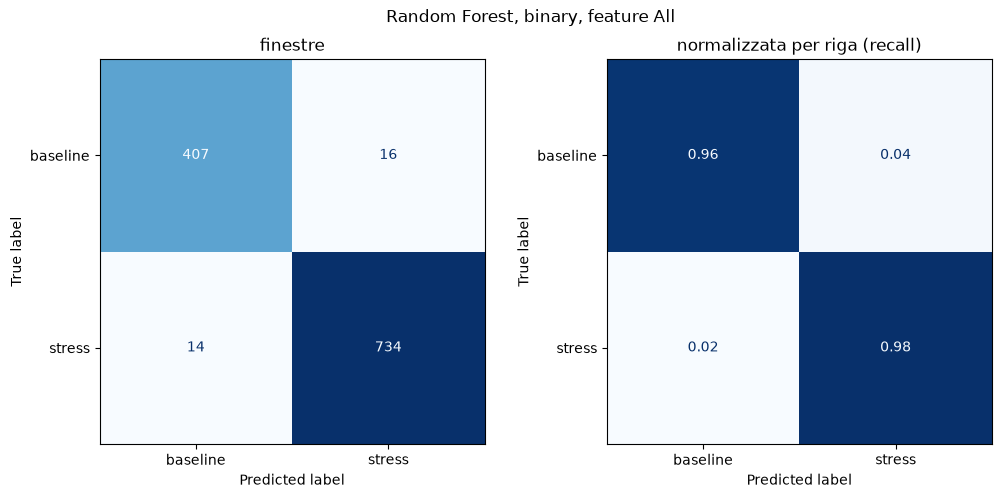


========== ternary (classi: ['baseline', 'cognitive+public', 'physical'], finestre: 1171)

-- media ± std sui fold LOSO
                   acc           f1
RF All     0.93 ± 0.07  0.93 ± 0.07
RF Physio  0.77 ± 0.10  0.76 ± 0.10
RF Motion  0.90 ± 0.08  0.89 ± 0.09
Dummy      0.36 ± 0.02  0.18 ± 0.01

-- fold esterni (feature All)
 subject  windows  acc   f1  max_depth  n_estimators
a360c459       58 0.81 0.77        NaN           300
f64f9403       59 0.80 0.80       10.0           100
89ba6f89       56 0.80 0.80        NaN           300
a5e823ad       55 0.84 0.81       10.0           300
f9513e4b       55 0.84 0.85       10.0           100
464cc459       57 0.91 0.91        NaN           100
7bb4dafd       46 0.93 0.91        NaN           300
d9af7d23       52 0.92 0.92        NaN           300
6df1a4f9       53 0.94 0.94       10.0           100
623f620e       58 0.95 0.94       10.0           300
937503f7       56 0.96 0.96        NaN           100
46b09d4a       57 0.96 0.97     

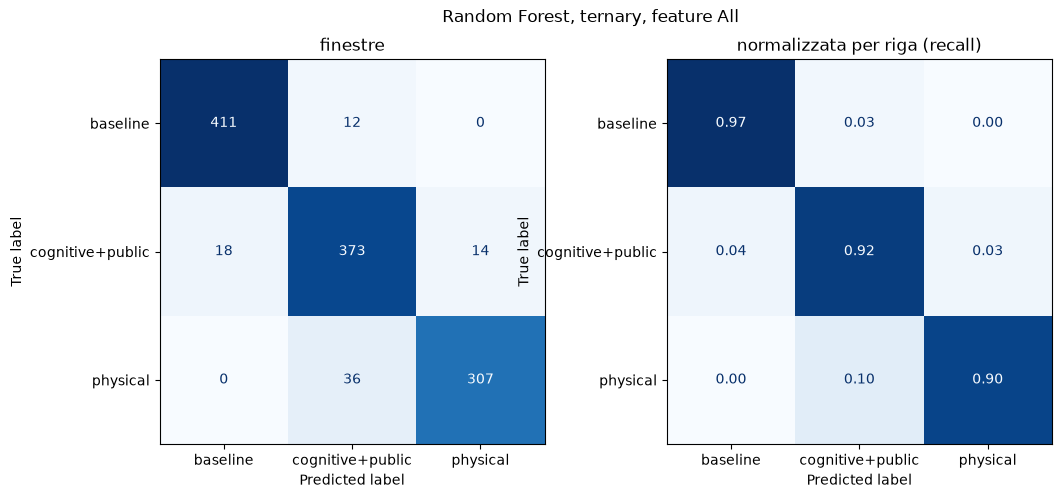


========== binary_no_physical (classi: ['baseline', 'stress'], finestre: 828)

-- media ± std sui fold LOSO
                   acc           f1
RF All     0.97 ± 0.05  0.97 ± 0.05
RF Physio  0.92 ± 0.11  0.92 ± 0.11
RF Motion  0.93 ± 0.08  0.93 ± 0.08
Dummy      0.51 ± 0.05  0.34 ± 0.02

-- fold esterni (feature All)
 subject  windows  acc   f1  max_depth  n_estimators
f9513e4b       39 0.82 0.82        NaN           100
89ba6f89       40 0.85 0.85        NaN           100
f64f9403       42 0.86 0.86        NaN           300
b61f4c2a       41 0.93 0.93        NaN           300
7bb4dafd       29 0.97 0.96        NaN           300
937503f7       39 0.97 0.97        NaN           300
464cc459       40 0.98 0.97        NaN           300
46b09d4a       40 0.98 0.97        NaN           300
a360c459       42 0.98 0.98        NaN           300
ddca342b       36 1.00 1.00        NaN           300
d9af7d23       36 1.00 1.00        NaN           300
c5a60768       41 1.00 1.00        NaN      

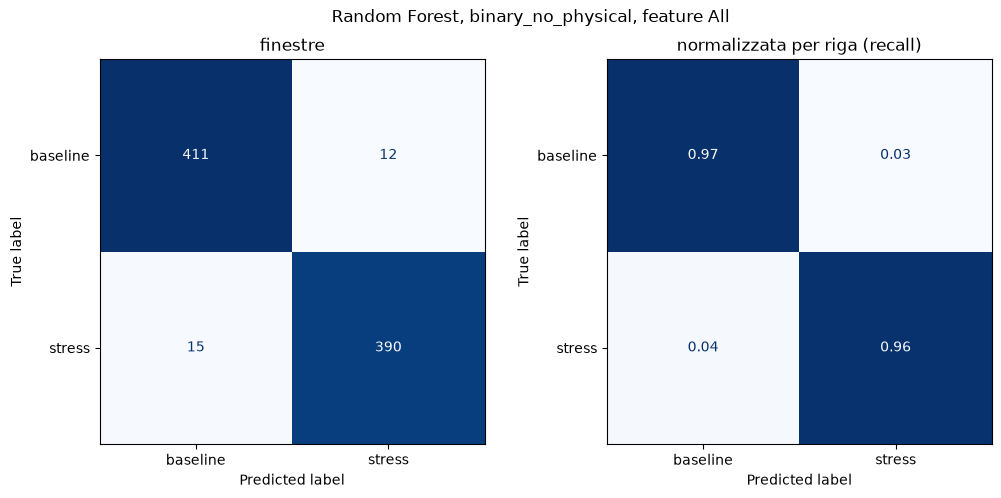

In [12]:
from datetime import date
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate

RF, GRID = CLASSIFIERS["Random Forest"]
# binario senza physical: con solo Physio dice se i segnali fisiologici colgono lo stress e non lo sforzo
RF_TASKS = {**TASKS, "binary_no_physical": {"baseline": "baseline", "cognitive": "stress", "public": "stress"}}


def grid_search():
    return GridSearchCV(RF, GRID, scoring="f1_macro", cv=LeaveOneGroupOut(), n_jobs=-1)


def nested_loso(X, y, groups, features):
    """Come loso_predictions, ma per ogni fold esterno (= soggetto di test) tiene anche
    iperparametri scelti, punteggi e permutation importance calcolata sul soggetto di test."""
    pred, folds, importance = np.empty_like(y), [], []
    for train, test in LeaveOneGroupOut().split(X, y, groups):
        search = grid_search().fit(X[train], y[train], groups=groups[train])
        pred[test] = search.predict(X[test])
        folds.append({"subject": groups[test[0]][3:11], "windows": len(test),
                      "acc": accuracy_score(y[test], pred[test]),
                      "f1": f1_score(y[test], pred[test], average="macro"), **search.best_params_})
        importance.append(permutation_importance(search, X[test], y[test], scoring="f1_macro",
                                                 n_repeats=10, random_state=42, n_jobs=-1).importances_mean)
    return pred, pd.DataFrame(folds), pd.DataFrame(importance, columns=features)

complete = table.dropna(subset=FEATURE_SETS["All"])
mean_std = lambda s: f"{s.mean():.2f} ± {s.std(ddof=0):.2f}"
print(f"\n\nRANDOM FOREST - APPROFONDIMENTO")

for task, mapping in RF_TASKS.items():
    data = complete[complete["phase"].isin(mapping)]  # solo le fasi del compito
    y, classes = data["phase"].map(mapping).factorize(sort=True)
    groups, X = data["subject"].to_numpy(), data[FEATURE_SETS["All"]].to_numpy()
    print(f"\n========== {task} (classi: {list(classes)}, finestre: {len(y)})")

    # 1) RF sui tre feature set + DummyClassifier (predice sempre la classe più frequente nel training)
    runs = {name: nested_loso(data[f].to_numpy(), y, groups, f) for name, f in FEATURE_SETS.items()}
    scores = {f"RF {name}": run[1][["acc", "f1"]] for name, run in runs.items()}
    dummy = cross_validate(DummyClassifier(), X, y, groups=groups, cv=LeaveOneGroupOut(),
                           scoring=["accuracy", "f1_macro"])
    scores["Dummy"] = pd.DataFrame({"acc": dummy["test_accuracy"], "f1": dummy["test_f1_macro"]})
    print("\n-- media ± std sui fold LOSO\n" + pd.DataFrame({k: v.apply(mean_std) for k, v in scores.items()}).T.to_string())

    # 2) fold esterni con tutte le feature: punteggi e iperparametri scelti in ognuno
    pred, folds, importance = runs["All"]
    print("\n-- fold esterni (feature All)\n" + folds.sort_values("f1").round(2).to_string(index=False))
    print("\n-- quante volte è stata scelta ogni combinazione\n" + folds.value_counts(list(GRID), dropna=False).to_string())

    # 3) modello finale: iperparametri migliori e importanza delle feature
    final = grid_search().fit(X, y, groups=groups)
    print(f"\n-- modello finale, iperparametri migliori: {final.best_params_}")
    print(pd.DataFrame(final.cv_results_)[["params", "mean_test_score", "std_test_score"]].round(3).to_string(index=False))
    weights = pd.DataFrame({"MDI": final.best_estimator_.feature_importances_,
                            "perm_mean": importance.mean(), "perm_std": importance.std(ddof=0)},
                           index=FEATURE_SETS["All"])
    print("\n-- importanza feature (MDI del modello finale, permutation sui soggetti di test)\n"
        + weights.sort_values("perm_mean", ascending=False).round(3).to_string())

    # 4) matrici di confusione aggregate sui fold esterni
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for a, norm, title in zip(ax, (None, "true"), ("finestre", "normalizzata per riga (recall)")):
        ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=classes, normalize=norm, cmap="Blues",
                                                colorbar=False, values_format=".2f" if norm else "d", ax=a)
        a.set_title(title)
    fig.suptitle(f"Random Forest, {task}, feature All")
    plt.show()